# Project 2 — Questions 1–4

**NYU Tandon · CS-GY 6643 · Computer Vision · Fall 2026**

**Team member(s):** To be added  
**NetID(s):** To be added

Classical computer vision solutions for runway detection, augmented reality, panorama stitching, and interactive segmentation. Q1 and Q2 are implemented below using the reviewed class material. Q3–Q4 remain placeholders for subsequent tasks.

## Setup and Input Data

Run this notebook from the project root with **Python (CV Project 2)**. On Colab, place the input folders in the current working directory. The source images are never modified; generated results go under `outputs/`. See `AGENTS.md` for requirements and `DATA_SOURCES.json` for input provenance.

In [1]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt

output_dir = Path("outputs/q1")
output_dir.mkdir(parents=True, exist_ok=True)

## Q1 — Geometric Structure Detection: Runway Boundaries

**5 points · Main handout p. 3**

Detect the two outer pavement–grass boundaries automatically and draw them on the original image. We use Gaussian smoothing, Canny edges, Otsu color thresholding, and RANSAC with total-least-squares refitting. All coordinates come from image evidence; no manual crop, clicked endpoints, or learned model is used.

### 1. Find edges with grass on one side

Grass is greener than the nearly neutral pavement in this image. Apply Otsu's automatic threshold to the **Lab a channel** (lower values are greener), creating a rough grass mask. It is a color cue, not a perfect semantic segmentation. Use Canny on smoothed grayscale to retain actual image edges. Around each edge, compare 5 × 5 grass-mask neighborhoods 10 pixels to its left and right. Keep edges where one neighborhood is at least 80% grass and the other at most 20% grass. This separates possible left/right borders and suppresses most pavement markings.

The small border exclusion only ensures that both neighborhoods fit in the image; it does not select a runway region. Pixel distances and thresholds below are processing parameters, not object coordinates.

In [2]:
image = cv2.cvtColor(cv2.imread("Q1 Data/Runway.jpg"), cv2.COLOR_BGR2RGB)
smooth = cv2.GaussianBlur(image, (5, 5), 1.2)
gray = cv2.cvtColor(smooth, cv2.COLOR_RGB2GRAY)
a_channel = cv2.cvtColor(smooth, cv2.COLOR_RGB2LAB)[..., 1]
_, grass = cv2.threshold(a_channel, 0, 1, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
edges = cv2.Canny(gray, 15, 45) > 0

# Compare grass coverage in patches 10 pixels to either side of each edge.
coverage = cv2.boxFilter(grass.astype(np.float32), -1, (5, 5))
left, right = np.roll(coverage, 10, axis=1), np.roll(coverage, -10, axis=1)
valid = np.zeros_like(edges)
valid[5:-5, 13:-13] = True  # Exclude incomplete patches and rolled borders.
candidates = [edges & valid & (left > 0.8) & (right < 0.2),
              edges & valid & (right > 0.8) & (left < 0.2)]

### 2. Fit the two boundary lines robustly

Adapt the Lecture 3 codelab's `ransac_line` and SVD refit. A line is represented by `a*x + b*y + c = 0`, normalized so `sqrt(a² + b²) = 1`; its absolute residual is therefore a perpendicular distance in pixels. For each grass-side group, sample two points, score all candidates, retain the largest consensus, and refit using its inliers. Ties use the smaller median residual. A fixed seed makes the calculation repeatable.

Use 1,000 trials and a 6-pixel tolerance to accommodate boundary roughness and mild departure from a straight line. These settings were chosen by inspecting this supplied image, not by hidden-label validation. The two dominant lines are then checked **together**: they must have shared vertical support, enclose positive width, and narrow toward the top. Segment endpoints use the 1st/99th percentiles of each line's supporting rows, avoiding extension to the image borders.

Left: 728/1443 inliers; RMS = 2.98 px
Right: 587/1311 inliers; RMS = 2.57 px


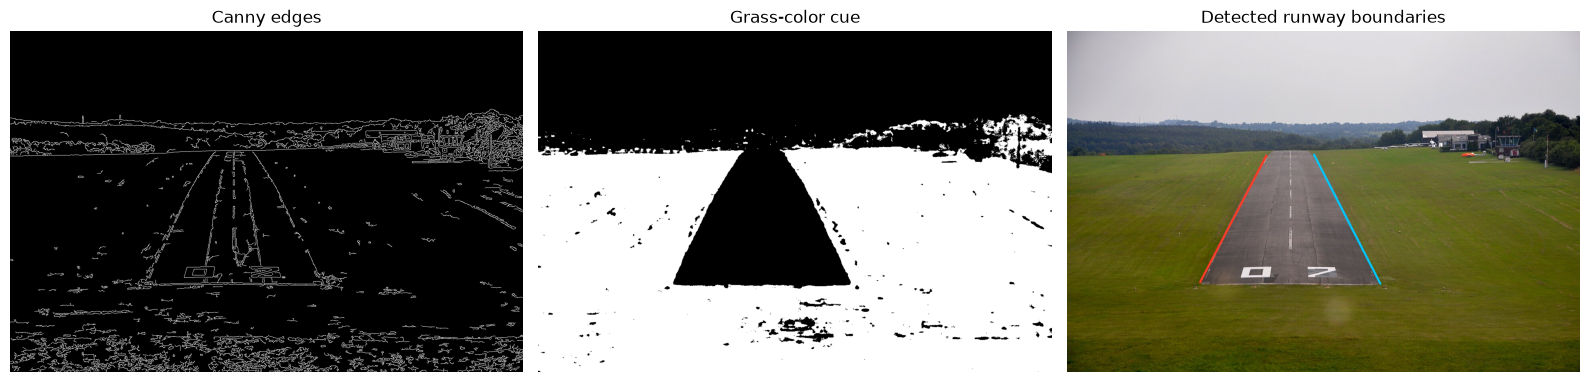

In [3]:
def ransac_boundary(points, threshold=6, trials=1000):
    """Two-point RANSAC followed by a total-least-squares line fit."""
    assert len(points) >= 2, "Too few boundary candidates."
    rng = np.random.default_rng(7)
    best_score = (-1, -np.inf)
    for _ in range(trials):
        p, q = points[rng.choice(len(points), 2, replace=False)]
        line = np.cross(np.r_[p, 1], np.r_[q, 1])
        line /= np.linalg.norm(line[:2])  # Sampled edge pixels are distinct.
        distances = np.abs(points @ line[:2] + line[2])
        inliers = distances < threshold
        score = (inliers.sum(), -np.median(distances[inliers]))
        if score > best_score:
            best_score, support = score, points[inliers]
    center = support.mean(axis=0)
    _, _, vt = np.linalg.svd(support - center, full_matrices=False)
    line = np.r_[vt[-1], -vt[-1] @ center]
    return line, np.abs(points @ line[:2] + line[2]) < threshold


colors = [(255, 60, 40), (0, 200, 255)]
annotated = image.copy()
lines, segments = [], []
for side, mask, color in zip(["Left", "Right"], candidates, colors):
    points = np.column_stack(np.where(mask)[::-1]).astype(float)
    line, inliers = ransac_boundary(points)
    rows = np.quantile(points[inliers, 1], [0.01, 0.99])
    xs = -(line[1] * rows + line[2]) / line[0]
    segment = np.column_stack([xs, rows])
    lines.append(line)
    segments.append(segment)
    start, end = np.rint(segment).astype(int)
    cv2.line(annotated, tuple(start), tuple(end), color, 3, cv2.LINE_AA)
    residuals = points[inliers] @ line[:2] + line[2]
    print(f"{side}: {inliers.sum()}/{len(points)} inliers; RMS = {np.sqrt(np.mean(residuals**2)):.2f} px")

# Check that both sides overlap vertically and widen toward the foreground.
lines, segments = np.array(lines), np.array(segments)
rows = np.array([segments[:, 0, 1].max(), segments[:, 1, 1].min()])
xs = -(lines[:, 1, None] * rows + lines[:, 2, None]) / lines[:, 0, None]
widths = xs[1] - xs[0]
assert rows[1] > rows[0] and 0 < widths[0] < widths[1], "Invalid boundary pair."
assert cv2.imwrite(str(output_dir / "runway_boundaries.png"), cv2.cvtColor(annotated, cv2.COLOR_RGB2BGR))

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, picture, title in zip(axes, [edges, grass, annotated],
                             ["Canny edges", "Grass-color cue", "Detected runway boundaries"]):
    ax.imshow(picture, cmap="gray")
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

### Q1 — Original-resolution images

Original image first, followed by the final annotated result. Both are embedded at **1280 × 850 pixels**, without resizing. The notebook viewer may scale them to fit its window.

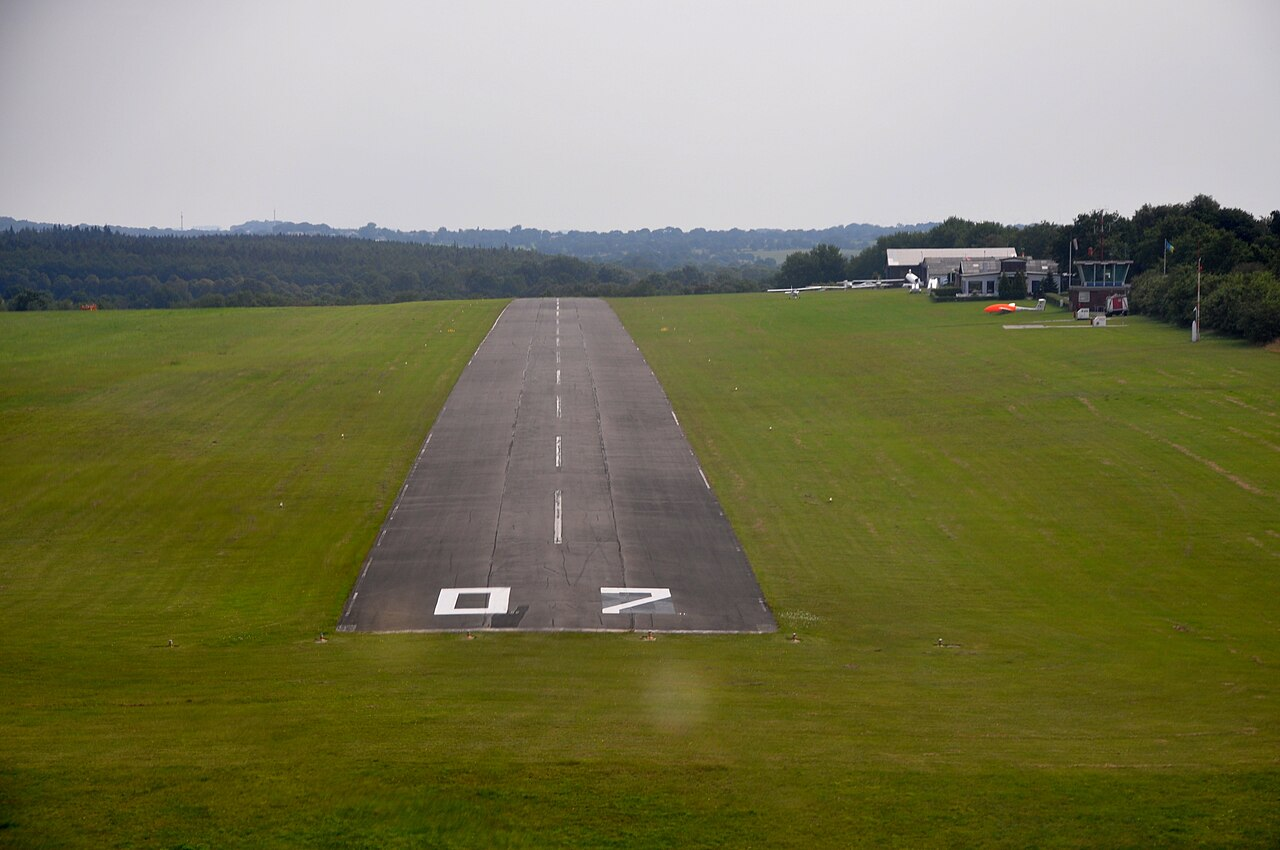

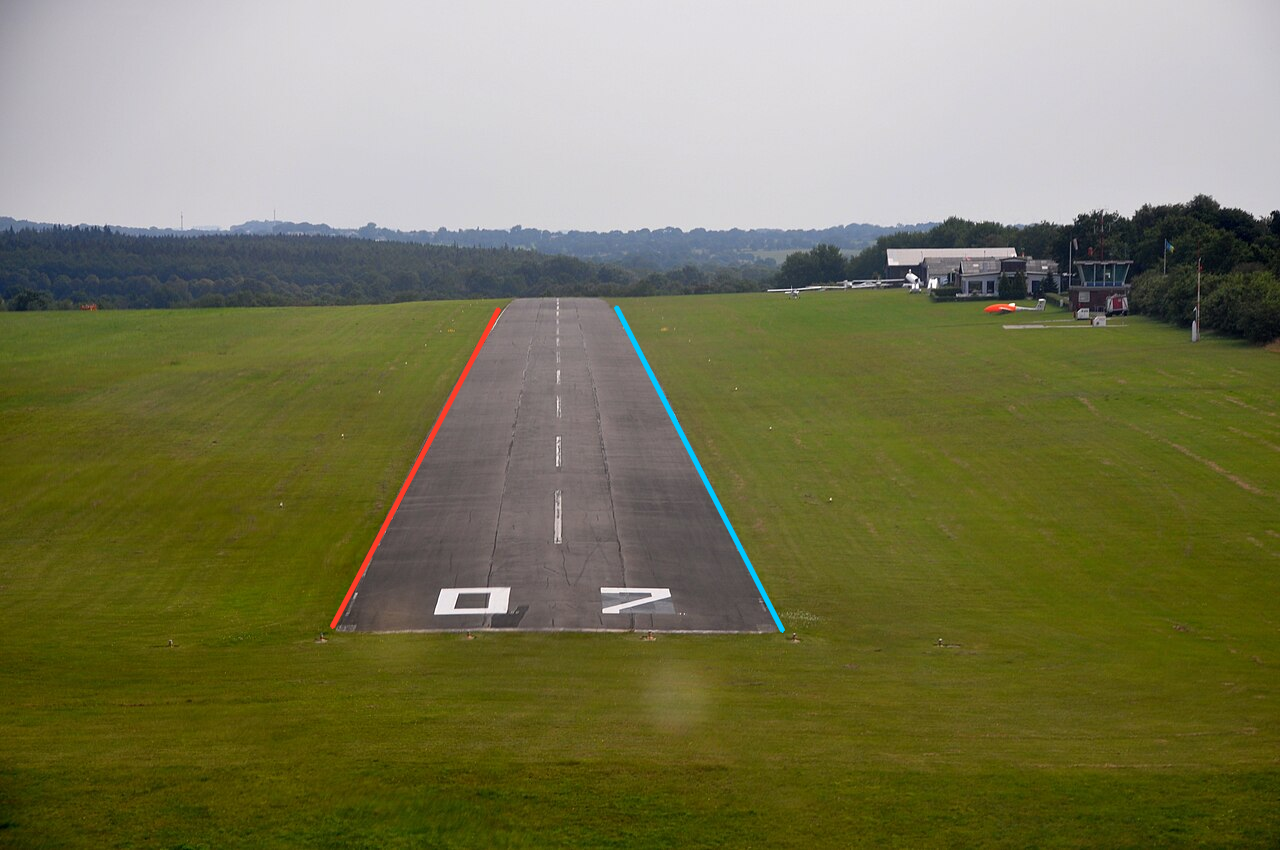

In [4]:
from IPython.display import Image as DisplayImage, display
display(DisplayImage(filename="Q1 Data/Runway.jpg"))
display(DisplayImage(filename=str(output_dir / "runway_boundaries.png")))

### Explanation of the result

The red and cyan segments follow the left and right pavement–grass interfaces. Color transitions suppress the centerline and runway numbers because their surrounding pavement has low grass membership on both sides. RANSAC rejects scattered candidates from vegetation, buildings, and other structures. The pair widens downward, consistent with the approaching-camera perspective.

The output preserves the original image dimensions and contains exactly two drawn line segments. Their endpoints are computed from edge support, rather than manually supplied corners. Only the supported portion is drawn; no additional lines or manually supplied endpoints are added.

**Limitations:** the photographed edges are rough and not perfectly straight. One line per side approximates that shape, especially near the distant end; percentile trimming can leave short unsupported end portions undrawn. The grass-color assumption may fail in different weather or scenery. The printed RMS residuals measure agreement with selected edge points, **not accuracy against the unavailable hidden ground truth**.

### Class sources and adaptations

- **Lecture 3**, pp. 27–52, and `CV_2026_Lecture_3.ipynb`, cells 6/8: normalized implicit lines, perpendicular residuals, random two-point hypotheses, consensus scoring and SVD refitting. The helper above is a shortened adaptation for distinct edge-pixel candidates.
- **Lecture 4**, pp. 70–74, and `Lecture4_Fitting_Transformations_and_Segmentation_Codelab_5.ipynb`, cell 20: thresholding, Canny edges and segmentation; color features also appear in cells 24/29.
- **Project-specific adaptations:** Otsu thresholding on the green–red Lab channel, opposite-side grass tests, separate candidate groups, the pair geometry check, and support-derived drawing extents. These choices are not presented as verbatim codelab code.

A grayscale-edge baseline with a stricter saturation cue missed distant border evidence. The final approach uses the Lab color cue with gentler Canny thresholds. Using the threshold-mask outline itself as an edge source introduced displaced grass/vegetation boundaries, so the final fit uses actual grayscale edges. No hidden labels were used to choose these settings.

## Q2 — Augmented Reality: Book Cover Replacement

**10 points · Main handout p. 4**

Find SIFT features in the source cover and scene, reject ambiguous matches with the **0.75 ratio test**, and estimate a **source → scene homography using RANSAC**. Feature extraction uses images with a 2,400-pixel longest side; matched coordinates are restored to original pixels before fitting. The RANSAC tolerance is five working-image pixels, scaled into scene pixels. No cover corners are manually selected.

**Class sources:** Lecture 3 pp. 27–52 (RANSAC); Lecture 4 pp. 34–56 (homographies, inverse warping and bilinear interpolation); `Lecture4_Fitting_Transformations_and_Segmentation_Codelab_5.ipynb`, cell 10 (SIFT, ratio test, `findHomography`). Resizing, coordinate restoration and mask compositing are project adaptations.

In [5]:
scene = cv2.imread('Q2 Data/Scene.png')
source = cv2.imread('Q2 Data/Source_Screen.png')
replacement = cv2.imread('Q2 Data/replacement_screen.jpg')
# Resize only for feature extraction; return matched points to original coordinates.
sift = cv2.SIFT_create()
keypoints, descriptors, scales = [], [], []
for picture in [source, scene]:
    h, w = picture.shape[:2]
    small = cv2.resize(picture, (round(w * 2400 / max(h, w)), round(h * 2400 / max(h, w))))
    kp, desc = sift.detectAndCompute(cv2.cvtColor(small, cv2.COLOR_BGR2GRAY), None)
    assert desc is not None and len(kp) >= 2, 'Insufficient image features.'
    keypoints.append(kp)
    descriptors.append(desc)
    scales.append(np.array([w, h]) / np.array(small.shape[1::-1]))
matches = cv2.BFMatcher().knnMatch(*descriptors, k=2)
good = [m for m, n in matches if m.distance < 0.75 * n.distance]
assert len(good) >= 4, 'Too few cover matches.'
p = np.float32([keypoints[0][m.queryIdx].pt for m in good]) * scales[0]
q = np.float32([keypoints[1][m.trainIdx].pt for m in good]) * scales[1]
cv2.setRNGSeed(7)
H, inliers = cv2.findHomography(p, q, cv2.RANSAC, 5 * max(scales[1]))
assert H is not None and inliers.sum() >= 4, 'Cover homography failed.'
projected = cv2.perspectiveTransform(p[:, None], H)[:, 0]
error = np.linalg.norm(projected - q, axis=1)[inliers.ravel().astype(bool)]
print(f'{inliers.sum()}/{len(good)} inliers; median reprojection error = {np.median(error):.2f} px')
h, w = source.shape[:2]
corners = cv2.perspectiveTransform(np.float32([[[0, 0], [w-1, 0], [w-1, h-1], [0, h-1]]]), H)[0]
assert np.isfinite(corners).all() and cv2.isContourConvex(corners), 'Invalid cover polygon.'

84/286 inliers; median reprojection error = 2.83 px


### Warp the replacement and composite

Resize the new artwork to the reference cover's dimensions, then warp it with the fitted homography. Warp a full-cover mask using nearest-neighbor interpolation and copy pixels only inside it. OpenCV uses inverse sampling internally; image interpolation is bilinear. All images here use OpenCV BGR until display.

The PNG is saved at the original scene resolution (**4284 × 5712**); the figure below is a display preview.

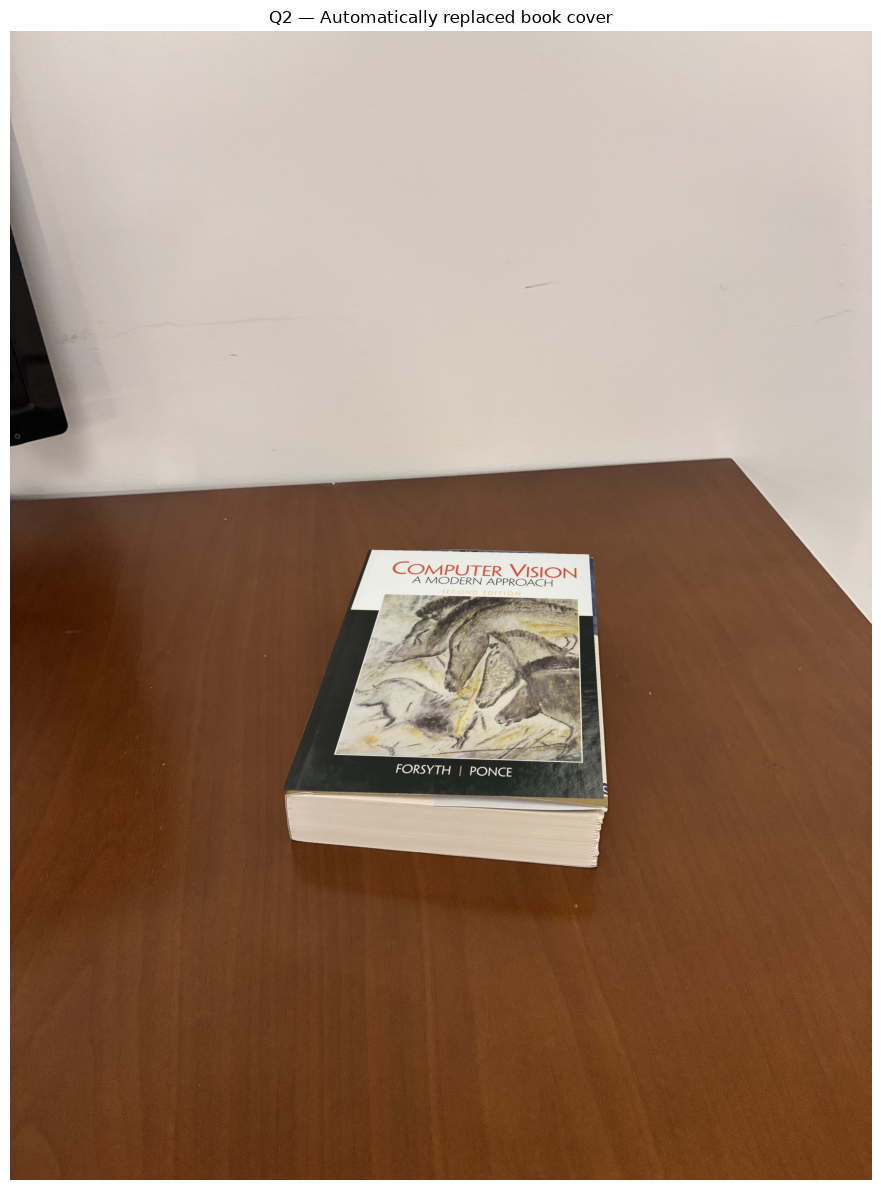

In [6]:
# Warp the artwork and mask from source-cover coordinates into the original scene.
size = scene.shape[1::-1]
warped = cv2.warpPerspective(cv2.resize(replacement, (w, h)), H, size,
                             flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REPLICATE)
mask = cv2.warpPerspective(np.full((h, w), 255, np.uint8), H, size, flags=cv2.INTER_NEAREST)
result = scene.copy()
result[mask > 0] = warped[mask > 0]
q2_dir = Path("outputs/q2")
q2_dir.mkdir(parents=True, exist_ok=True)
assert cv2.imwrite(str(q2_dir / "replaced_cover.png"), result)
assert np.array_equal(result[mask == 0], scene[mask == 0])
plt.figure(figsize=(9, 12))
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title("Q2 — Automatically replaced book cover")
plt.axis("off")
plt.tight_layout()
plt.show()

### Explanation of the result

RANSAC retains consistent cover correspondences and rejects mismatches on repeated letters/artwork and the background. Their homography gives the replacement its perspective automatically. The supplied source alpha channel is fully opaque, so its full rectangle defines the mask. Pixels outside the computed mask remain **exactly unchanged**; the page block and surrounding scene are preserved in the displayed result.

**Measured fit:** 84 of 286 ratio-test matches are inliers, with a median reprojection error of **2.83 original-scene pixels**. This measures matched-point alignment, not ground-truth corner accuracy.

**Limitation:** the physical cover is slightly curved. A single planar homography leaves narrow strips of the original artwork along parts of the top/right/bottom boundary and can cross the edge slightly elsewhere. Thus this minimal class-based solution does not achieve pixel-perfect full-cover replacement. The different artwork aspect ratio is intentionally stretched to fit the reference cover.

## Q3 — Panoramic Image Stitching

**10 points · Main handout pp. 1, 5**

Inputs: all six `Q3 Data/Q3_Image_*.jpg` images. This section will identify/correct the two distorted views, determine overlap and order, estimate transformations, calculate the panorama canvas and offsets, and blend all six views. It will display the panorama and explain the explicit pipeline. Filename order is not panorama order; one-call stitchers such as `cv2.Stitcher` are prohibited.

## Q4 — Interactive Segmentation Using User Clicks

**10 points · Main handout p. 6**

Inputs: three `Q4 Data/Q4_Image_*.jpg` images and `Q4 Data/clicks.json`. This section will use the supplied `(x, y)` clicks as definitive foreground seeds and save/display one RGBA PNG cutout per animal instance on a transparent background. It will explain the classical method and discuss mask quality. No manually drawn masks or deep-learning models.

## Foundations for Q5

After Q1–Q4 are solved, summarize the relevant geometric estimation, correspondence, segmentation, and mask-handling concepts that can support `CellMatchingSegmentation.ipynb`. Record transfer limits and cite the supplied lectures/codelabs. No Q5 solution has been implemented.

## AI Assistance and References

OpenAI Codex assisted with setup, source review, and Q1–Q2 implementation/explanations. Class references are listed with each solution. The actual user prompt chain follows.

### AI Assistance Record — Project 2

## Tools and scope

During initial setup on 2026-10-06, OpenAI Codex assisted with reading the previous project's workflow and both Project 2 handouts, preparing project instructions, downloading official Q1–Q4 data, initializing the Python environment, and creating Markdown-only notebook scaffolds. No question was solved during setup. Later source review and Q1 implementation are recorded chronologically below.

Keep actual user prompts in chronological order. Add subsequent assistance here and include the required disclosure/prompt chain in final deliverables. Do not reconstruct unavailable prompts or include hidden model reasoning.

## Request 1 — 2026-10-06

The user referenced `../Project1/AGENTS.md` and attached a screenshot of the previous project's directory structure. The request text was:

> Go through the AGENTS.md file for the previous project of this course, we will be following similar workflow for this project as well. Understand the requirements for this project by going through the project material present in the two pdfs present in the project root. Create a AGENTS.md file similar to one uploaded from the previous project with emaphasis on simple and minila code, we will follow the similar project structure as the project 1. For this task create the directories and download the data for Q1-4 we will solve this in subsequent tasks and the solutions and concepts used in it will the foundation upon which will we solve the kaggle competition problem. Also initialize the virtual python environment and install the required libraries. Add basic README.md we wont update it  until after the project solution is finished and ready to submit. Just create the solution notebooks and just add Heading markdown cells with boilerplate information about what it contains don't add code yet. In next tasks I will provide the lecture slides and the codelab notbooks the concepts and code from will we will use to solve this assignment.

## Request 2 — 2026-10-06

> Commit and push the repository to [https://github.com/rohitfarfad/-CV-Cell-Matching-x-Segmentation.git](https://github.com/rohitfarfad/-CV-Cell-Matching-x-Segmentation.git)

Assistance: inspect the local and remote Git state, prepare the initial setup commit, and push it to the user-specified repository. Existing dataset, environment, and generated-output exclusions are retained.

## Request 3 — 2026-10-08

The user supplied Lecture 3, 4, 5, and 6 PDFs; their exact paths are recorded in `AGENTS.md` §6.

> Go through this slides and understand the concepts covered  in the lectures. Update the AGENTS.md briefly to use these concepts in the solutions

Assistance: review the four slide decks, map their concepts to Q1–Q5, and record the later deadline extension and Q5-specific guidance. No solution code or notebook changes.

## Request 4 — 2026-10-08

The message listed the four lecture PDFs; the corresponding local code notebooks were found in `../Lectures/CodeLabs/` and are identified in `AGENTS.md` §6.1.

> Go through these codelabs and understand the code and concepts discussed. We will use this code to solve the porblems.

Assistance: review four relevant local codelabs, record reusable snippets and adaptation issues, and check the supplied RLE functions on five synthetic masks. The solution notebooks and README were not changed; no models were downloaded or trained.

## Request 5 — 2026-10-08

> Using the concepts covered in the class, how do you solve the Question 1, give the overview of the approach before we code it

Assistance: explain a classical approach combining edge detection, pavement–grass color evidence, RANSAC line fitting, and pair geometry checks. No code was added in that turn.

## Request 6 — 2026-10-08

> great, let's code it in the notebook

Assistance: implement Q1 in `Q1to4Solution.ipynb`, adapting class RANSAC/SVD, Canny, thresholding and color-feature concepts; inspect the programmatically annotated result and retain diagnostics and explanations. Q2–Q5 and README remain unchanged. No hidden ground truth, manual coordinates, or learned models are used.

Validation: the notebook executed in a fresh kernel without cell errors, saved the annotated image and visible figures, and passed original-input hash and unchanged-placeholder checks. Residuals describe the fitted edge consensus, not hidden-ground-truth accuracy.

## Request 7 — 2026-10-08

> Use minimum code

## Request 8 — 2026-10-08

> Continue, use minimal tokens

Assistance: reduced Q1 from 133 to 67 nonblank code lines, removed redundant plots/table dependencies, and reran the notebook. The generated boundary image is byte-identical to the previous result.

## Request 9 — 2026-10-08

> For question1, add the final solution images in origianl image resolution and after that give the overview of the solution for question 2 using concepts covered in the class

Assistance: embed the original and annotated Q1 images at native 1280 × 850 resolution; outline SIFT matching, RANSAC homography estimation, perspective warping and mask-based compositing for Q2. No Q2 solution code added.

## Request 10 — 2026-10-08

> Great, add the solution for question 2 in the notebook with minimum code and optimizing the token usage

Assistance: implement a concise SIFT/ratio-test/RANSAC homography solution, warp and composite the replacement at original scene resolution, inspect the result, and document the small boundary mismatch caused by the curved cover. No manual coordinates or learned methods; README and Q3–Q5 remain unchanged.


## Final Submission Review

Before submission, add team names/NetIDs, restart and run all cells in order, keep all outputs visible, and verify that each question contains its computed final result and explanation. Submit one accessible Colab notebook link on Brightspace. Q1 and Q2 have executed code and results; Q3–Q4 still require implementation.